In [ ]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import torch
from torch.utils.data import TensorDataset, DataLoader
import shap
import sys
from pathlib import Path

current_dir = Path().resolve()
sys.path.append(str(current_dir.parent))

# 📌 외부 파일에서 딥러닝 모델 클래스 임포트
from models import ChurnLSTM, ChurnCNN1D, ChurnTransformer

# ==========================================
# 🚀 1. 경로 및 최적 하이브리드 설정 로드
# ==========================================
DATA_DIR = "../data/data/split"
ML_MODEL_DIR = "../model/machine_learning"
DL_MODEL_DIR = "../model/deep_learning"
EVAL_DIR = "../test"
TEST_CSV_PATH = "../data/data/split/test_20181101_v1.csv"
TEST_NPY_PATH = "../data/data/split/test.npy"

# 이전 단계에서 저장된 최적 하이브리드 설정 로드
config_path = os.path.join(EVAL_DIR, "best_hybrid_config.json")
with open(config_path, "r", encoding="utf-8") as f:
    hybrid_config = json.load(f)

best_ml_name = hybrid_config["best_ml_model"]
best_dl_name = hybrid_config["best_dl_model"]
ml_weight = hybrid_config["ml_weight"]
dl_weight = hybrid_config["dl_weight"]
best_threshold = hybrid_config["best_threshold"]

print(f"📌 [설정 로드 완료] ML: {best_ml_name} ({ml_weight:.2f}), DL: {best_dl_name} ({dl_weight:.2f}), 임계값: {best_threshold:.4f}")

# ==========================================
# 🚀 2. 테스트 데이터 정비 및 모델 로드
# ==========================================
df_test = pd.read_csv(TEST_CSV_PATH)
X_seq_test = np.load(TEST_NPY_PATH)

target_col = "churn" if "churn" in df_test.columns else ("is_churn" if "is_churn" in df_test.columns else df_test.columns[-1])
y_true = df_test[target_col].values.ravel()

drop_cols = [target_col, "user_id", "userId", "page_sequence", "session_item_sequence", "padded_sequence"]
feature_cols = [col for col in df_test.columns if col not in drop_cols]
X_tab_test = df_test[feature_cols].copy()

# 범주형 및 객체형 데이터 인코딩
for col in ["gender", "level", "last_page", "level_last"]:
    if col in X_tab_test.columns:
        X_tab_test[col] = X_tab_test[col].astype("category").cat.codes

for col in X_tab_test.columns:
    if X_tab_test[col].dtype == "object":
        X_tab_test[col] = pd.to_numeric(X_tab_test[col], errors="coerce").fillna(0.0)

# 머신러닝 모델 로드
ml_model_path = os.path.join(ML_MODEL_DIR, best_ml_name)
if best_ml_name.endswith(".pkl"):
    ml_model = joblib.load(ml_model_path)
elif best_ml_name.endswith(".cbm"):
    from catboost import CatBoostClassifier
    ml_model = CatBoostClassifier()
    ml_model.load_model(ml_model_path)

# 딥러닝 모델 로드
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dl_model_path = os.path.join(DL_MODEL_DIR, best_dl_name)

if "lstm" in best_dl_name.lower():
    dl_model = ChurnLSTM(vocab_size=50, embedding_dim=32, hidden_dim=64).to(device)
elif "cnn" in best_dl_name.lower():
    dl_model = ChurnCNN1D(vocab_size=50, embedding_dim=32, num_filters=64).to(device)
elif "transformer" in best_dl_name.lower():
    dl_model = ChurnTransformer(vocab_size=50, embedding_dim=32, num_heads=4, hidden_dim=64, num_layers=2, dropout=0.1).to(device)

dl_model.load_state_dict(torch.load(dl_model_path, map_location=device))
dl_model.eval()

# ==========================================
# 🚀 3. 예측 수행
# ==========================================
n_feat = getattr(ml_model, "n_features_in_", X_tab_test.shape[1])
ml_preds = ml_model.predict_proba(X_tab_test.iloc[:, :n_feat])[:, 1]

test_dataset = TensorDataset(torch.tensor(X_seq_test, dtype=torch.long), torch.tensor(y_true, dtype=torch.float32))
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)
dl_preds_list = []
with torch.no_grad():
    for seqs, _ in test_loader:
        outputs = torch.sigmoid(dl_model(seqs.to(device)))
        dl_preds_list.extend(outputs.cpu().numpy())
dl_preds = np.array(dl_preds_list).ravel()

# 하이브리드 최종 예측 산출
hybrid_preds = (ml_weight * ml_preds) + (dl_weight * dl_preds)
predicted_churn = (hybrid_preds >= best_threshold).astype(int)

# ==========================================
# 🚀 4. SHAP 계산 및 이탈 유저 데이터 가공·저장
# ==========================================
print("⏳ SHAP Explainer 계산 및 이탈 유저 분석 데이터 생성 중...")
try:
    background_data = X_tab_test.iloc[:50, :n_feat]
    explainer = shap.PermutationExplainer(ml_model.predict_proba, background_data)
    shap_explanation = explainer(X_tab_test.iloc[:, :n_feat])
    
    if len(shap_explanation.values.shape) == 3:
        shap_vals_target = shap_explanation.values[:, :, 1]
    else:
        shap_vals_target = shap_explanation.values
    use_shap = True
except Exception as e:
    print(f"⚠️ SHAP 계산 경고 (기본 중요도로 대체됩니다): {e}")
    use_shap = False

# 이탈로 판정된 유저 인덱스 추출
churn_indices = np.where(predicted_churn == 1)[0]
print(f"🔍 총 {len(df_test)}명 중 {len(churn_indices)}명의 유저가 이탈 위험군으로 예측되었습니다.")

churned_records = []
for idx in churn_indices:
    user_id = df_test.iloc[idx].get("user_id", df_test.iloc[idx].get("userId", f"Index_{idx}"))
    
    record = {
        "user_id": user_id,
        "test_index": int(idx),
        "hybrid_churn_prob": float(hybrid_preds[idx]),
        "ml_score": float(ml_preds[idx]),
        "dl_score": float(dl_preds[idx]),
        "actual_label": int(y_true[idx])
    }
    
    # SHAP 기여도를 바탕으로 가장 이탈에 큰 영향을 준 상위 3개 요인 추출
    if use_shap:
        user_shap = shap_vals_target[idx]
        feature_impacts = sorted(
            zip(X_tab_test.columns[:n_feat], user_shap, X_tab_test.iloc[idx, :n_feat]),
            key=lambda x: abs(x[1]),
            reverse=True
        )
        for rank, (col, impact, val) in enumerate(feature_impacts[:3], 1):
            record[f"top{rank}_feature"] = col
            record[f"top{rank}_value"] = val
            record[f"top{rank}_shap_impact"] = impact
            
    churned_records.append(record)

# DataFrame 변환 및 CSV 저장
df_churned_report = pd.DataFrame(churned_records)
output_csv_path = os.path.join(EVAL_DIR, "churned_users_analysis.csv")
df_churned_report.to_csv(output_csv_path, index=False, encoding="utf-8-sig")

print(f"✅ 이탈 유저 분석 및 저장 완료! 파일 경로: {output_csv_path}")

📌 [설정 로드 완료] ML: ab_model.pkl (0.60), DL: lstm_model_weights.pth (0.40), 임계값: 0.3982
⏳ SHAP Explainer 계산 및 이탈 유저 분석 데이터 생성 중...


PermutationExplainer explainer: 2722it [15:51,  2.83it/s]                          

🔍 총 2721명 중 646명의 유저가 이탈 위험군으로 예측되었습니다.
✅ 이탈 유저 분석 및 저장 완료! 파일 경로: ./test\churned_users_analysis.csv


In [4]:
import os
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

In [ ]:
# ==========================================
# 🚀 1. 데이터 로드
# ==========================================
EVAL_DIR = "../test"
csv_path = os.path.join(EVAL_DIR, "churned_users_analysis.csv")

if not os.path.exists(csv_path):
    raise FileNotFoundError(f"'{csv_path}' 파일이 존재하지 않습니다. 이탈 분석 저장 코드를 먼저 실행해 주세요.")

df_churned = pd.read_csv(csv_path)
print(f"✅ 이탈 유저 데이터 로드 완료! 총 유저 수: {len(df_churned)}명")

if len(df_churned) == 0:
    print("⚠️ 시각화할 이탈 유저 데이터가 없습니다.")
else:
    # ==========================================
    # 🚀 2. Plotly 서브플롯 레이아웃 구성 (2x2)
    # ==========================================
    fig = make_subplots(
        rows=2, cols=2,
        subplot_titles=(
            "하이브리드 이탈 예측 확률 분포",
            "이탈에 가장 큰 영향을 준 주요 피처 (TOP 1)",
            "ML 점수 vs DL 점수 상관관계",
            "실제 이탈 여부별 예측 확률 비교"
        ),
        vertical_spacing=0.15,
        horizontal_spacing=0.1
    )

    # ------------------------------------------
    # [그래프 1] 하이브리드 이탈 예측 확률 분포 (Histogram)
    # ------------------------------------------
    fig.add_trace(
        go.Histogram(
            x=df_churned['hybrid_churn_prob'],
            marker_color='crimson',
            name='확률 분포',
            opacity=0.75
        ),
        row=1, col=1
    )

    # ------------------------------------------
    # [그래프 2] 가장 큰 영향을 미친 이탈 원인 피처 TOP 5 (Bar)
    # ------------------------------------------
    if 'top1_feature' in df_churned.columns:
        top_features = df_churned['top1_feature'].value_counts().head(5).reset_index()
        top_features.columns = ['feature', 'count']
        
        fig.add_trace(
            go.Bar(
                x=top_features['count'],
                y=top_features['feature'],
                orientation='h',
                marker_color='firebrick',
                name='피처 빈도'
            ),
            row=1, col=2
        )
        fig.update_yaxes(categoryorder='total ascending', row=1, col=2)

    # ------------------------------------------
    # [그래프 3] 머신러닝 점수 vs 딥러닝 점수 상관관계 (Scatter)
    # ------------------------------------------
    fig.add_trace(
        go.Scatter(
            x=df_churned['ml_score'],
            y=df_churned['dl_score'],
            mode='markers',
            marker=dict(color='darkorange', size=8, opacity=0.7),
            text=df_churned['user_id'] if 'user_id' in df_churned.columns else None,
            name='유저별 점수'
        ),
        row=2, col=1
    )
    # 대각선 기준선 추가
    fig.add_trace(
        go.Scatter(
            x=[0, 1], y=[0, 1],
            mode='lines',
            line=dict(dash='dash', color='gray'),
            name='기준선',
            showlegend=False
        ),
        row=2, col=1
    )

    # ------------------------------------------
    # [그래프 4] 실제 이탈 여부별 예측 확률 비교 (Box)
    # ------------------------------------------
    if 'actual_label' in df_churned.columns:
        df_churned['label_str'] = df_churned['actual_label'].map({0: '유지 (0)', 1: '이탈 (1)'})
        for label in df_churned['label_str'].unique():
            subset = df_churned[df_churned['label_str'] == label]
            fig.add_trace(
                go.Box(
                    y=subset['hybrid_churn_prob'],
                    name=str(label),
                    boxmean=True
                ),
                row=2, col=2
            )

    # ==========================================
    # 🚀 3. 전체 레이아웃 디자인 및 저장
    # ==========================================
    fig.update_layout(
        title_text="<b>🚨 이탈 위험군 유저 다차원 분석 인터랙티브 리포트</b>",
        title_font_size=18,
        showlegend=False,
        height=900,
        width=1200,
        template="plotly_white"
    )

    # 축 레이블 설정
    fig.update_xaxes(title_text="이탈 예측 확률 (Hybrid Score)", row=1, col=1)
    fig.update_yaxes(title_text="유저 수", row=1, col=1)

    fig.update_xaxes(title_text="발생 빈도 (유저 수)", row=1, col=2)
    fig.update_yaxes(title_text="피처 이름", row=1, col=2)

    fig.update_xaxes(title_text="머신러닝 예측 점수", row=2, col=1)
    fig.update_yaxes(title_text="딥러닝 예측 점수", row=2, col=1)

    fig.update_xaxes(title_text="실제 레이블", row=2, col=2)
    fig.update_yaxes(title_text="하이브리드 이탈 확률", row=2, col=2)

    # 인터랙티브 HTML 파일로 저장
    output_html_path = os.path.join(EVAL_DIR, "churn_analysis_interactive.html")
    fig.write_html(output_html_path)
    print(f"✅ 인터랙티브 시각화 HTML 저장 완료: {output_html_path}")

    # 주피터 노트북 환경 출력
    fig.show()

✅ 이탈 유저 데이터 로드 완료! 총 유저 수: 646명
✅ 인터랙티브 시각화 HTML 저장 완료: ./test\churn_analysis_interactive.html


📊 SHAP 요약 비즈웜(Beeswarm) 플롯 생성 중...


C:\Users\playdata2\AppData\Local\Temp\ipykernel_20168\2838076124.py:13: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_vals_target, X_tab_test.iloc[:, :n_feat], show=False)
C:\Users\playdata2\AppData\Local\Temp\ipykernel_20168\2838076124.py:16: UserWarning: Glyph 128680 (\N{POLICE CARS REVOLVING LIGHT}) missing from font(s) Malgun Gothic.
  plt.tight_layout()
C:\Users\playdata2\AppData\Local\Temp\ipykernel_20168\2838076124.py:20: UserWarning: Glyph 128680 (\N{POLICE CARS REVOLVING LIGHT}) missing from font(s) Malgun Gothic.
  plt.savefig(output_shap_path, dpi=300, bbox_inches='tight')
c:\Users\playdata2\miniconda3\envs\agent\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128680 (\N{POLICE CARS REVOLVING LIGHT}) missing from font(s) Malgun Gothic.
  fig.canvas.print_

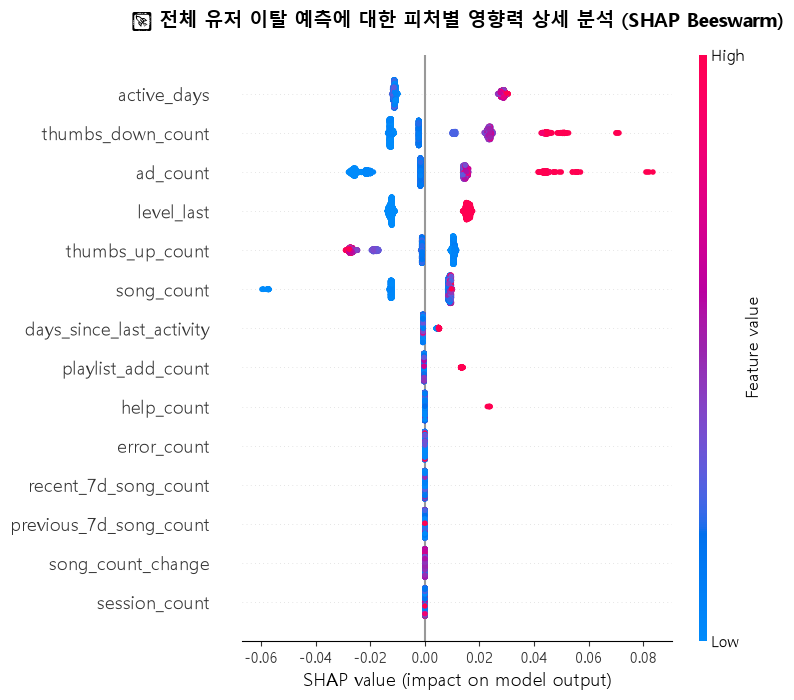

✅ 상세 SHAP 시각화 저장 완료: ./test\churn_shap_beeswarm.png


In [6]:
import shap
import matplotlib.pyplot as plt

# 한글 폰트 설정
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# SHAP Explainer가 이미 정의되어 있다는 가정하에 실행
print("📊 SHAP 요약 비즈웜(Beeswarm) 플롯 생성 중...")

plt.figure(figsize=(10, 8))
# 전체 피처에 대한 영향력과 값의 상관관계를 한눈에 보여주는 비즈웜 그래프
shap.summary_plot(shap_vals_target, X_tab_test.iloc[:, :n_feat], show=False)

plt.title("🚨 전체 유저 이탈 예측에 대한 피처별 영향력 상세 분석 (SHAP Beeswarm)", fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()

# 이미지 저장
output_shap_path = os.path.join(EVAL_DIR, "churn_shap_beeswarm.png")
plt.savefig(output_shap_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"✅ 상세 SHAP 시각화 저장 완료: {output_shap_path}")